In [1]:
import pandas as pd
csv_file_path = r"/content/UpdatedResumeDataSet.csv"
df = pd.read_csv(csv_file_path)

# Display basic info about the dataset
df.info(), df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  962 non-null    object
 1   Resume    962 non-null    object
dtypes: object(2)
memory usage: 15.2+ KB


(None,
        Category                                             Resume
 0  Data Science  Skills * Programming Languages: Python (pandas...
 1  Data Science  Education Details \r\nMay 2013 to May 2017 B.E...
 2  Data Science  Areas of Interest Deep Learning, Control Syste...
 3  Data Science  Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
 4  Data Science  Education Details \r\n MCA   YMCAUST,  Faridab...)

<ipython-input-2-d952dbad2401>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values, palette="viridis")


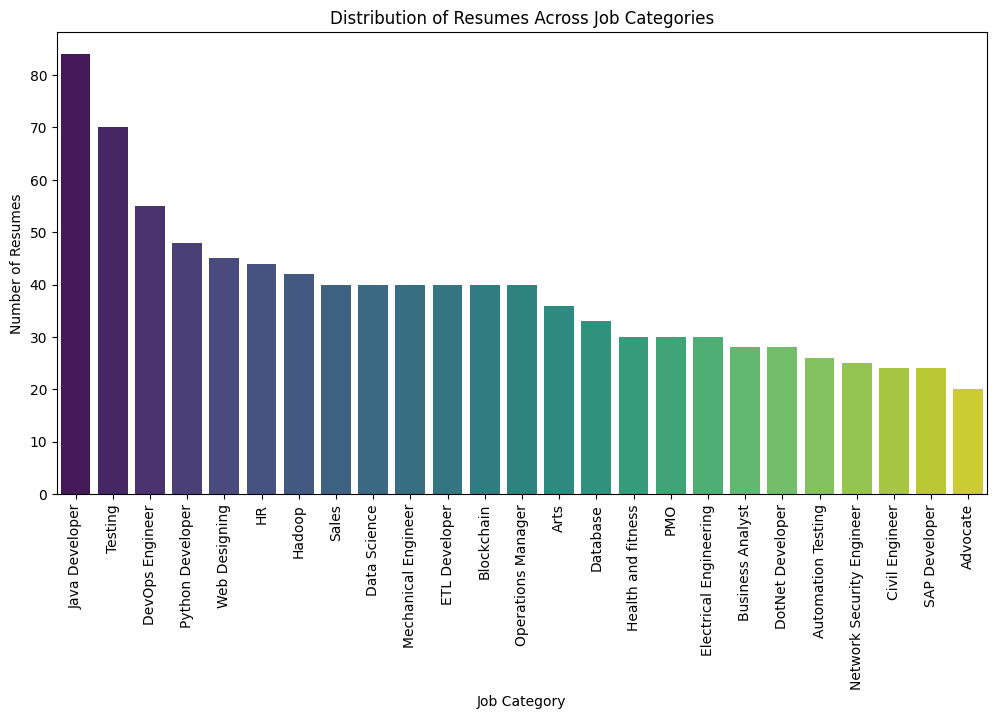

,count
Category,
Java Developer,84
Testing,70
DevOps Engineer,55
Python Developer,48
Web Designing,45


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the number of resumes per category
category_counts = df["Category"].value_counts()

# Plot category distribution
plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.index, y=category_counts.values, palette="viridis")
plt.xticks(rotation=90)
plt.xlabel("Job Category")
plt.ylabel("Number of Resumes")
plt.title("Distribution of Resumes Across Job Categories")
plt.show()

# Display top 5 categories with highest count
category_counts.head()


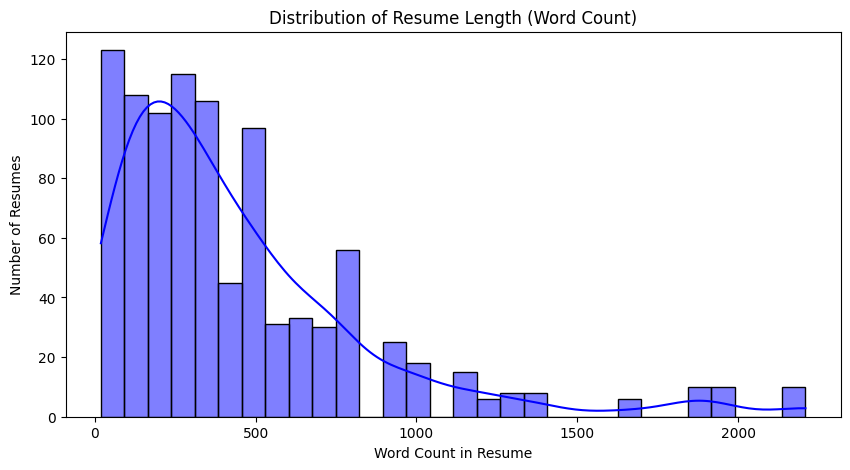

,Resume_Word_Count
count,962.000000
mean,450.497921
std,415.868459
min,19.000000
25%,166.000000
50%,329.000000
75%,589.250000
max,2209.000000


In [3]:
# Calculate word count for each resume
df["Resume_Word_Count"] = df["Resume"].apply(lambda x: len(str(x).split()))

# Plot word count distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["Resume_Word_Count"], bins=30, kde=True, color="blue")
plt.xlabel("Word Count in Resume")
plt.ylabel("Number of Resumes")
plt.title("Distribution of Resume Length (Word Count)")
plt.show()

# Display basic statistics on word count
df["Resume_Word_Count"].describe()


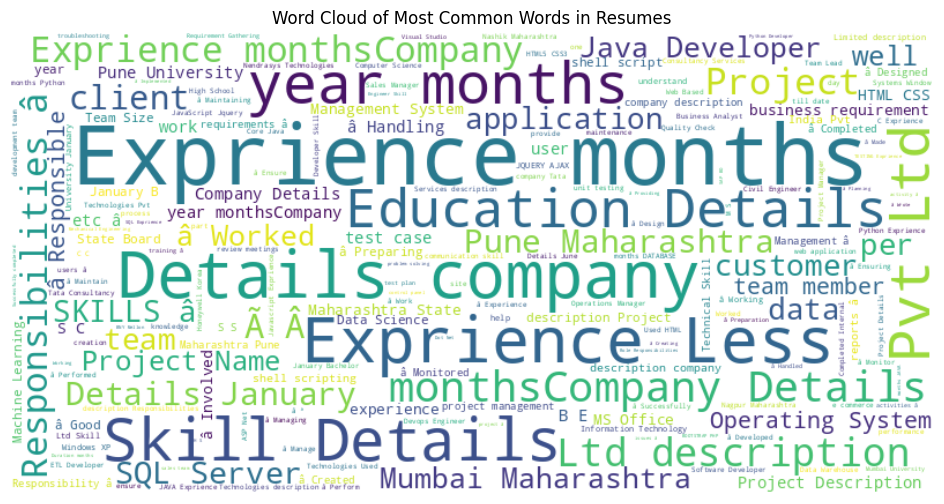

In [4]:
from wordcloud import WordCloud

# Combine all resumes into a single text corpus
text_corpus = " ".join(df["Resume"].astype(str))

# Generate word cloud
plt.figure(figsize=(12, 6))
wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate(text_corpus)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Most Common Words in Resumes")
plt.show()


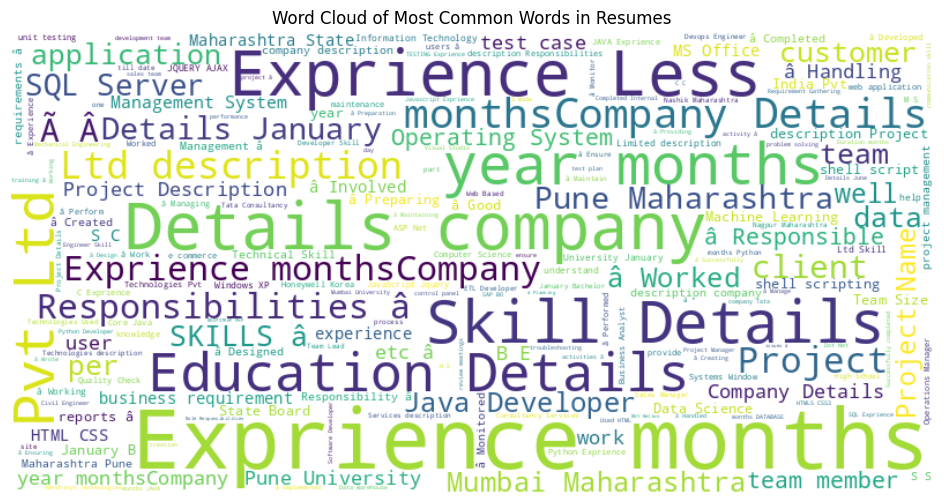

In [5]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine all resumes into a single text corpus
text_corpus = " ".join(df["Resume"].astype(str))

# Generate word cloud
plt.figure(figsize=(12, 6))
wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate(text_corpus)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Most Common Words in Resumes")
plt.show()


In [6]:
from collections import Counter
import nltk
from nltk.corpus import stopwords

# Download stopwords if not already available
nltk.download('stopwords')

# Define stopwords
stop_words = set(stopwords.words('english'))

# Tokenize words and remove stopwords
words = text_corpus.lower().split()
filtered_words = [word for word in words if word.isalpha() and word not in stop_words]

# Count word frequencies
word_freq = Counter(filtered_words)

# Display top 20 words
print(word_freq.most_common(20))


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


[('exprience', 3829), ('company', 3336), ('months', 3182), ('details', 3051), ('project', 2989), ('description', 2692), ('data', 1940), ('team', 1582), ('management', 1414), ('maharashtra', 1356), ('year', 1272), ('less', 1145), ('business', 1119), ('using', 1116), ('january', 1090), ('skill', 1080), ('system', 990), ('testing', 989), ('test', 980), ('engineering', 973)]


<ipython-input-7-662599994b68>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Category", y="Resume_Word_Count", data=df, palette="coolwarm")


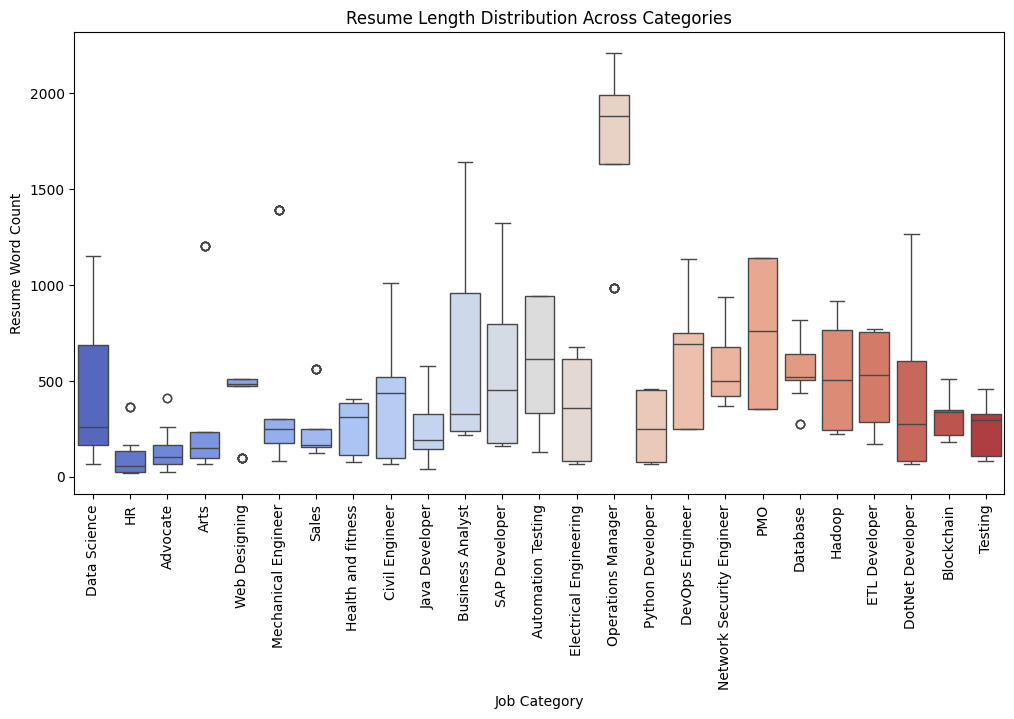

In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(x="Category", y="Resume_Word_Count", data=df, palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("Job Category")
plt.ylabel("Resume Word Count")
plt.title("Resume Length Distribution Across Categories")
plt.show()


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

# Extract bigrams
vectorizer = CountVectorizer(ngram_range=(2,2), stop_words='english')
X = vectorizer.fit_transform(df["Resume"])

# Count occurrences
bigram_counts = X.sum(axis=0).A1
bigram_features = vectorizer.get_feature_names_out()

# Sort and display top 20 bigrams
bigram_freq = sorted(zip(bigram_features, bigram_counts), key=lambda x: x[1], reverse=True)
print(bigram_freq[:20])


[('details company', np.int64(1194)), ('exprience year', np.int64(1137)), ('skill details', np.int64(962)), ('year months', np.int64(919)), ('exprience months', np.int64(864)), ('education details', np.int64(779)), ('monthscompany details', np.int64(746)), ('pvt description', np.int64(486)), ('details january', np.int64(407)), ('pune maharashtra', np.int64(394)), ('sql server', np.int64(364)), ('java developer', np.int64(286)), ('mumbai maharashtra', np.int64(279)), ('exprience monthscompany', np.int64(275)), ('project description', np.int64(240)), ('description project', np.int64(236)), ('exprience 24', np.int64(236)), ('year monthscompany', np.int64(224)), ('pune university', np.int64(222)), ('team members', np.int64(217))]


In [9]:
df["Cleaned_Resume"] = df["Resume"].str.lower().str.replace(r'[^\w\s]', '', regex=True)

# Group by category and extract common words
category_skills = df.groupby("Category")["Cleaned_Resume"].apply(lambda x: Counter(" ".join(x).split()).most_common(10))

# Convert to dictionary for better readability
category_skills_dict = category_skills.to_dict()

# Print top 10 skills per category
for category, skills in category_skills_dict.items():
    print(f"\nCategory: {category}")
    print("Top Skills:", skills)



Category: Advocate
Top Skills: [('of', 96), ('and', 96), ('â', 76), ('details', 60), ('to', 58), ('legal', 50), ('law', 46), ('in', 44), ('university', 38), ('advocate', 34)]

Category: Arts
Top Skills: [('and', 588), ('the', 360), ('of', 300), ('ã', 300), ('in', 204), ('to', 180), ('company', 156), ('arts', 144), ('for', 138), ('a', 114)]

Category: Automation Testing
Top Skills: [('and', 850), ('â', 642), ('test', 392), ('testing', 342), ('of', 286), ('automation', 272), ('in', 248), ('to', 182), ('the', 164), ('with', 146)]

Category: Blockchain
Top Skills: [('and', 424), ('company', 256), ('â', 240), ('blockchain', 224), ('on', 224), ('description', 208), ('exprience', 192), ('of', 184), ('months', 160), ('in', 128)]

Category: Business Analyst
Top Skills: [('the', 804), ('â', 796), ('and', 764), ('of', 402), ('to', 366), ('for', 258), ('business', 252), ('in', 218), ('with', 218), ('test', 208)]

Category: Civil Engineer
Top Skills: [('and', 412), ('the', 380), ('â', 324), ('of',

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")

# Fit and transform resumes
X_tfidf = vectorizer.fit_transform(df["Resume"])

# Display feature names (top 10)
print(vectorizer.get_feature_names_out()[:10])


['000' '01' '02' '03' '04' '04th' '05' '050education' '06th' '07']


In [ ]:
# store the tfidf vectorizer in file and save it


In [11]:
# prompt: # store the tfidf vectorizer in file and save it

import pickle
# ... (your existing code)

# Initialize TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")

# Fit and transform resumes
X_tfidf = vectorizer.fit_transform(df["Resume"])

# Display feature names (top 10)
print(vectorizer.get_feature_names_out()[:10])

# Save the vectorizer to a file
filename = 'tfidf_vectorizer.pkl'
pickle.dump(vectorizer, open(filename, 'wb'))


['000' '01' '02' '03' '04' '04th' '05' '050education' '06th' '07']


In [12]:
# prompt: Train a classification model  Logistic Regression and store the model

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import pickle

csv_file_path = r"/content/UpdatedResumeDataSet.csv"
df = pd.read_csv(csv_file_path)

# ... (Your existing code for data preprocessing)

# Initialize TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")

# Fit and transform resumes
X_tfidf = vectorizer.fit_transform(df["Resume"])

# Save the vectorizer to a file
filename = 'tfidf_vectorizer.pkl'
pickle.dump(vectorizer, open(filename, 'wb'))

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, df['Category'], test_size=0.2, random_state=42)

# Initialize and train the Logistic Regression model
model = LogisticRegression(max_iter=1000)  # Increased max_iter
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")
print(classification_report(y_test, y_pred))


# Save the trained model to a file
model_filename = 'resume_classifier_model.pkl'
pickle.dump(model, open(model_filename, 'wb'))


Accuracy: 0.9948186528497409
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         3
                     Arts       1.00      1.00      1.00         6
       Automation Testing       1.00      1.00      1.00         5
               Blockchain       1.00      1.00      1.00         7
         Business Analyst       1.00      1.00      1.00         4
           Civil Engineer       1.00      1.00      1.00         9
             Data Science       1.00      1.00      1.00         5
                 Database       1.00      1.00      1.00         8
          DevOps Engineer       1.00      0.93      0.96        14
         DotNet Developer       1.00      1.00      1.00         5
            ETL Developer       1.00      1.00      1.00         7
   Electrical Engineering       1.00      1.00      1.00         6
                       HR       1.00      1.00      1.00        12
                   Hadoop       